# Writing a new sample class

Two short recipes:

1. a new **tracer** — subclass `Tracer` (or `HaloSample`, ...) and declare `required_keys`;
2. a new **field** — subclass `Field` (or `MatterField`, ...) and declare `default_key`.

Everything else (table interface, selections, HDF5 io, `to_field` / `to_tracer`, use in `WCCF1D` / `WCCF3D`) is inherited. The examples run on a synthetic box.

In [9]:
%matplotlib inline
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
plt.style.use('default')
import pywccf

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 15, 'legend.fontsize': 12, 'axes.linewidth': 1.6,
    'legend.frameon': False, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True, 'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6, 'ytick.major.size': 6, 'xtick.minor.size': 3, 'ytick.minor.size': 3,
})

In [10]:
from pywccf import Tracer, Field, WCCF1D, WCCF3D
from pywccf.utils import synthetic_box

matter, tf, halos = synthetic_box(n_grids=64, l_box=128.0, n_halos=40_000, R_s=2.0, seed=0)
mesh = tf.mesh

## 1. A tracer: `VoidSample`

What a subclass needs:

* `required_keys` — checked at construction (`position` must always be there, shape (N, 3));
* properties / methods that read columns with `self[key]` (or `self._need(key)`, which raises a clear `KeyError`);
* nothing else: `subset*` return the subclass (a shallow copy keeps extra attributes), `from_file(path)` reads any file that uses the same keys.

Keep the shared keys (`position`, `mass`, `id`, `central`, `host_id`) for the shared meaning; add your own for the rest.

In [11]:
class VoidSample(Tracer):
    """Spherical voids: centre ``position`` and effective ``radius`` [h^-1 Mpc]."""

    required_keys = ("position", "radius")

    @property
    def radii(self) -> np.ndarray:
        return np.asarray(self["radius"], dtype=np.float64)

    @property
    def volumes(self) -> np.ndarray:
        return 4.0 / 3.0 * np.pi * self.radii ** 3

    def larger_than(self, r_min: float) -> "VoidSample":
        return self.subset_by_val("radius", lo=r_min)

    def volume_filling_fraction(self) -> float:
        return float(self.volumes.sum() / self.l_box ** 3)

Build it from your own arrays — here: local minima of the smoothed density, with a radius set by how deep they are.

In [12]:
from scipy.ndimage import minimum_filter

d8 = matter.smoothed(R=4.0)
is_min = (d8 == minimum_filter(d8, size=5, mode='wrap')) & (d8 < -0.3)
idx = np.argwhere(is_min)
voids = VoidSample({'position': idx * mesh.l_grid,
                    'radius': 6.0 * (-d8[is_min]) ** 0.5,
                    'delta_min': d8[is_min]},
                   l_box=mesh.l_box)

big = voids.larger_than(4.0)
print(type(big).__name__, len(voids), '->', len(big), '| VFF =', round(big.volume_filling_fraction(), 3))
try:
    VoidSample({'position': idx * mesh.l_grid})            # 'radius' missing
except KeyError as err:
    print('KeyError:', err)

[VoidSample] 102 objects, keys=('position', 'radius', 'delta_min')
VoidSample 102 -> 60 | VFF = 0.01
KeyError: "VoidSample needs keys ['radius']"


Inherited behaviour: file io, conversion to a field, and the WCCF estimators (here: where void centres sit around each web type).

VoidSample(n_objs=60, keys=('delta_min', 'position', 'radius')) | same radii: True
[MatterField] Mesh(n_grids=64, l_box=128), keys=('rho', 'delta')
MatterField(Mesh(n_grids=64, l_box=128), keys=('rho', 'delta')) | <delta> = 0.0


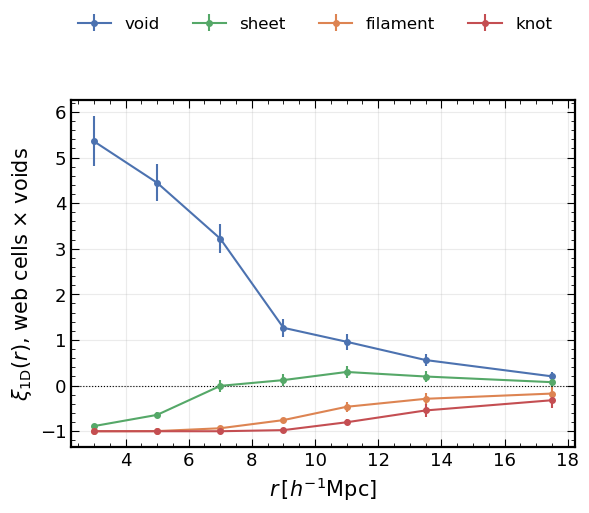

In [13]:
import tempfile
from pathlib import Path

p = big.to_file(Path(tempfile.mkdtemp()) / 'voids.h5')
back = VoidSample.from_file(p, verbose=False)
print(back, '| same radii:', np.allclose(back.radii, big.radii))

f = big.to_field(mesh, scheme='tsc', weight='radius')     # any column can be the weight
print(f, '| <delta> =', f.delta.mean().round(12))

w1 = WCCF1D(tf, big, edges=[2, 4, 6, 8, 10, 12, 15, 20], verbose=False)
res = w1.compute_all(error='jackknife', n_jk_side=2)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for web, c in zip(pywccf.WEB_TYPES, ['#4c72b0', '#55a868', '#dd8452', '#c44e52']):
    r = res[web]['all']
    ax.errorbar(r.r[1:], r.xi[1:], r.xi_sd[1:], color=c, marker='o', ms=4, capsize=0, label=web)
ax.axhline(0, color='k', lw=0.8, ls=':')
ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$'); ax.set_ylabel(r'$\xi_{\rm 1D}(r)$, web cells $\times$ voids')
ax.grid(True, which='major', alpha=0.25)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=4)

## 2. A field: `VelocityField`

What a subclass needs:

* `default_key` — the array used when no key is given (`value()`, `values_at()`, `smoothed()`, `to_tracer()`);
* arrays may carry trailing axes (here a 3-vector per node); the first three axes must be `mesh.shape`;
* derived quantities as methods; a classmethod constructor if the field is built from something else.

Below, a peculiar-velocity field: mass-weighted from a tracer (momentum / mass on the mesh), plus its divergence $\theta=\nabla\cdot\mathbf{v}$ by FFT.

In [14]:
class VelocityField(Field):
    """Peculiar velocity ``v`` (n, n, n, 3) [km/s]."""

    default_key = "v"

    @classmethod
    def from_tracer(cls, tracer, mesh, *, scheme="cic", vel_key="velocity", min_weight=1e-8, **kw):
        """Mass-weighted velocity: assign m v and m, divide (empty nodes -> 0)."""
        from pywccf.core import assign
        xs, m, v = tracer.positions, tracer.masses, np.asarray(tracer[vel_key], float)
        rho = assign(xs, mesh, weights=m, scheme=scheme)
        mom = np.stack([assign(xs, mesh, weights=m * v[:, i], scheme=scheme) for i in range(3)], -1)
        vel = np.where(rho[..., None] > min_weight * m.mean(), mom / np.maximum(rho, 1e-300)[..., None], 0.0)
        return cls({"v": vel, "rho": rho}, mesh, **kw)

    def divergence(self, R: float = 0.0) -> np.ndarray:
        """theta = div v [km/s / (h^-1 Mpc)], optionally Gaussian-smoothed."""
        vk = np.fft.rfftn(self["v"], axes=(0, 1, 2))
        kx, ky, kz = self.mesh.k_axes()
        th = 1j * (kx * vk[..., 0] + ky * vk[..., 1] + kz * vk[..., 2])
        if R > 0:
            th *= np.exp(-0.5 * self.mesh.k2() * R * R)
        return np.fft.irfftn(th, s=self.mesh.shape, axes=(0, 1, 2))

The synthetic halos have no velocities; give them the linear-theory flow of the density, $\mathbf{v}(\mathbf{k}) = i\,aHf\,\mathbf{k}\,\delta(\mathbf{k})/k^2$ (with $aHf=50$ km/s per $h^{-1}$Mpc), so that $\theta=-aHf\,\delta$ on large scales.

VelocityField(Mesh(n_grids=64, l_box=128), keys=('v', 'rho')) | v at the first halos: [[-39.4, 5.0, -16.7], [-46.1, -7.3, -21.2]]


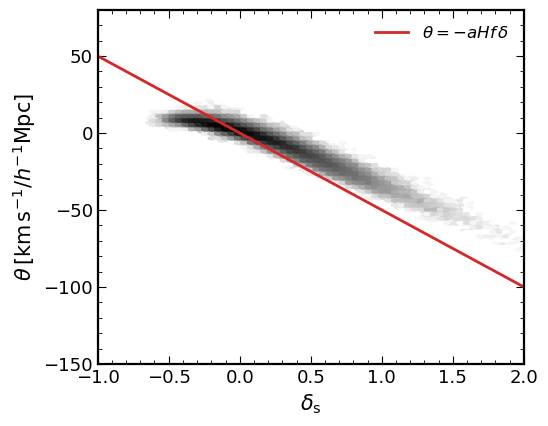

In [15]:
aHf = 50.0
dk = np.fft.rfftn(matter.smoothed(R=2.0))
k2 = mesh.k2(); k2[0, 0, 0] = 1.0
v_lin = np.stack([np.fft.irfftn(1j * aHf * k * dk / k2, s=mesh.shape, axes=(0, 1, 2)) for k in mesh.k_axes()], -1)
halos['velocity'] = pywccf.core.interpolate(v_lin, halos.positions, mesh, 'cic')

vf = VelocityField.from_tracer(halos, mesh, verbose=False)
theta = vf.divergence(R=4.0)
print(vf, '| v at the first halos:', vf.values_at(halos.positions[:2], scheme='cic').round(1).tolist())

fig, ax = plt.subplots(figsize=(5.5, 4.6))
sel = vf['rho'] > 0
ax.hexbin(matter.smoothed(R=4.0)[sel], theta[sel], gridsize=60, bins='log', cmap='Greys')
x = np.linspace(-1, 2, 2); ax.plot(x, -aHf * x, 'C3', lw=2, label=r'$\theta=-aHf\,\delta$')
ax.set_xlim(-1, 2); ax.set_ylim(-150, 80)
ax.set_xlabel(r'$\delta_{\rm s}$'); ax.set_ylabel(r'$\theta\,[{\rm km\,s^{-1}}/h^{-1}{\rm Mpc}]$')
ax.legend()

A scalar derived from the new field can be correlated with the web like any other field: put it in a `Field` (or a field subclass) on the tidal mesh and pass it to `WCCF1D` (FFT convolution). With `field_is_overdensity=True` the values are used as they are — the result is the mean velocity divergence at distance $r$ from the web cells.

In [16]:
theta_field = Field({'theta': theta}, mesh, verbose=False)
w1v = WCCF1D(tf, field=theta_field, field_key='theta', field_is_overdensity=True,
             edges=[2, 4, 6, 8, 10, 12, 15, 20], verbose=False)
for web in pywccf.WEB_TYPES[::-1]:
    r = w1v.compute(web, error='none')['all']
    print(f'{web:9s}', np.round(r.xi[1:], 1))

knot      [-17.1 -14.4 -11.2  -8.3  -6.1  -4.3  -2.8]
filament  [-5.7 -5.1 -4.5 -3.7 -3.  -2.3 -1.5]
sheet     [3.2 2.7 2.2 1.7 1.3 1.  0.6]
void      [7.2 6.8 6.2 5.5 4.7 3.8 2.6]


## Checklist

| | tracer | field |
|---|---|---|
| base class | `Tracer`, `HaloSample`, ... | `Field`, `MatterField`, ... |
| declare | `required_keys` | `default_key` |
| data | dict of (N, ...) arrays, `position` (N, 3) | dict of (n, n, n, ...) arrays on a `Mesh` |
| constructor | `Cls(data, l_box=...)`, `Cls.from_file(path)` | `Cls(data, mesh)`, `Cls.from_file(path)` |
| inherited | selections, hosts, `weights`, `to_field`, io | `values_at`, `smoothed`, `overdensity`, `to_tracer`, io |
| in the estimators | `WCCF1D(tf, tracer)`, `WCCF3D(tf, tracer)` | `WCCF1D(tf, field=...)`, `WCCF3D(tf, field=...)` |